# 3D Transformation Activity

Solids and transformations, using the same surface meshes, cube faces, and matrices as the basis notebooks.

**Solids**
1. Cone with height = 10 and radius = 8
2. Cube with edge = 5 and initial point at (3, 6, 4)

**Transformations**
1. Translate the cone by `[5, 7, 2]`
2. Rotate the cube by θ = 75° about the y-axis

A point is stored in homogeneous coordinates as `(x, y, z, 1)`. Each transformation is a 4×4 matrix:

| Rxx  Rxy  Rxz  Tx |
| Ryx  Ryy  Ryz  Ty |
| Rzx  Rzy  Rzz  Tz |
|  0    0    0   1  |

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

np.set_printoptions(precision=4, suppress=True)

def style_axes(ax, title, xlim, ylim, zlim):
    ax.set_title(title)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_zlim(*zlim)
    ax.set_box_aspect((xlim[1] - xlim[0], ylim[1] - ylim[0], zlim[1] - zlim[0]))
    ax.view_init(elev=22, azim=35)

## 1. Cone

Height `h = 10`, base radius `r = 8`. The base is on `z = 0` and the tip is at `z = h`. The radius falls linearly from the base to the tip:

`R(z) = r * (1 - z / h)`

`x = R(z) cos θ`, `y = R(z) sin θ`

In [2]:
# DRAWING A CONE
# Parameters for the cone
radius = 8
height = 10
num_points = 50

# Mesh of angle (theta) and height (z)
theta = np.linspace(0, 2 * np.pi, num_points)
z = np.linspace(0, height, num_points)
theta, Z = np.meshgrid(theta, z)

# Parametric equations for the cone
X = radius * (1 - Z / height) * np.cos(theta)
Y = radius * (1 - Z / height) * np.sin(theta)

print(f"Cone: radius = {radius}, height = {height}")
print(f"Base center (0, 0, 0), tip (0, 0, {height})")

Cone: radius = 8, height = 10
Base center (0, 0, 0), tip (0, 0, 10)


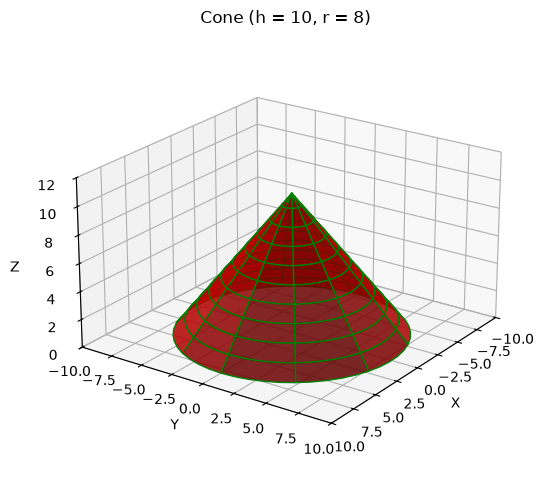

In [3]:
# Plot the cone
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, rstride=5, cstride=5, color='red', edgecolor='green', alpha=0.85)
style_axes(ax, 'Cone (h = 10, r = 8)', (-10, 10), (-10, 10), (0, 12))
plt.tight_layout()
plt.show()

In [4]:
# Volume of the cone
# V = (1/3) * pi * r^2 * h
def volume_cone(radius, height):
    return (1 / 3) * math.pi * radius**2 * height

print("Volume of Cone:", volume_cone(radius, height), "cubic units")

Volume of Cone: 670.2064327658225 cubic units


## Translate the cone by [5, 7, 2]

Translation matrix:

| 1  0  0  tx |
| 0  1  0  ty |
| 0  0  1  tz |
| 0  0  0  1  |

`(tx, ty, tz) = (5, 7, 2)`, so `(x', y', z') = (x + 5, y + 7, z + 2)`.

The base center moves from `(0, 0, 0)` to `(5, 7, 2)`. The tip moves from `(0, 0, 10)` to `(5, 7, 12)`.

Translation matrix:
[[1 0 0 5]
 [0 1 0 7]
 [0 0 1 2]
 [0 0 0 1]]
Base center -> [5 7 2]
Tip         -> [ 5  7 12]


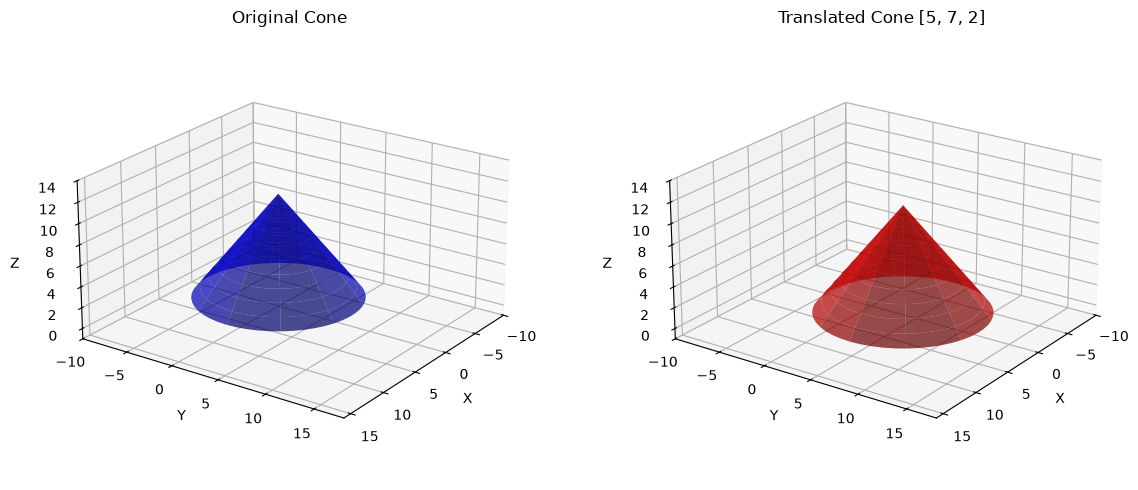

In [5]:
# Translation vector (tx, ty, tz)
translation = [5, 7, 2]
tx, ty, tz = translation

translation_matrix = np.array([
    [1, 0, 0, tx],
    [0, 1, 0, ty],
    [0, 0, 1, tz],
    [0, 0, 0, 1],
])
print("Translation matrix:")
print(translation_matrix)

# Apply translation
X_translated = X + tx
Y_translated = Y + ty
Z_translated = Z + tz

# Check the matrix on the base center and the tip
base_center = np.array([0, 0, 0, 1])
tip = np.array([0, 0, height, 1])
print("Base center ->", (translation_matrix @ base_center)[:3])
print("Tip         ->", (translation_matrix @ tip)[:3])

cone_limits = ((-10, 16), (-10, 18), (-1, 14))

fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(X, Y, Z, rstride=5, cstride=5, color='blue', alpha=0.7)
style_axes(ax1, 'Original Cone', *cone_limits)

ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X_translated, Y_translated, Z_translated, rstride=5, cstride=5, color='red', alpha=0.7)
style_axes(ax2, 'Translated Cone [5, 7, 2]', *cone_limits)

plt.tight_layout()
plt.show()

## 2. Cube

Edge = 5. The initial corner is `(3, 6, 4)`. The other seven corners are that point plus 5 along the axes.

`V = edge³ = 125` cubic units.

Initial corner: [3. 6. 4.]
Edge: 5
Vertices:
[[ 3.  6.  4.]
 [ 8.  6.  4.]
 [ 8. 11.  4.]
 [ 3. 11.  4.]
 [ 3.  6.  9.]
 [ 8.  6.  9.]
 [ 8. 11.  9.]
 [ 3. 11.  9.]]
Volume of Cube: 125 cubic units


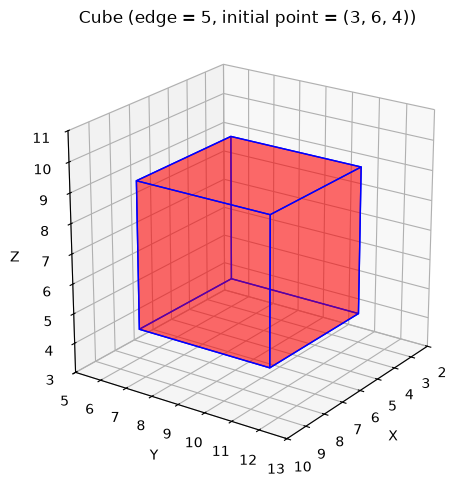

In [6]:
# DRAWING A CUBE
initial_corner = np.array([3, 6, 4], dtype=float)
edge_length = 5

vertices = np.array([
    initial_corner,
    initial_corner + [edge_length, 0, 0],
    initial_corner + [edge_length, edge_length, 0],
    initial_corner + [0, edge_length, 0],
    initial_corner + [0, 0, edge_length],
    initial_corner + [edge_length, 0, edge_length],
    initial_corner + [edge_length, edge_length, edge_length],
    initial_corner + [0, edge_length, edge_length],
])

face_indices = [
    [0, 1, 2, 3],  # Bottom
    [4, 5, 6, 7],  # Top
    [0, 1, 5, 4],  # Front
    [2, 3, 7, 6],  # Back
    [1, 2, 6, 5],  # Right
    [4, 7, 3, 0],  # Left
]

def cube_faces(points):
    return [[points[i] for i in face] for face in face_indices]

faces = cube_faces(vertices)

print("Initial corner:", initial_corner)
print("Edge:", edge_length)
print("Vertices:")
print(vertices)

def volume_cube(side):
    return side**3

print("Volume of Cube:", volume_cube(edge_length), "cubic units")

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection='3d')
ax.add_collection3d(Poly3DCollection(
    faces, facecolors='red', linewidths=1, edgecolors='blue', alpha=0.35
))
style_axes(ax, 'Cube (edge = 5, initial point = (3, 6, 4))', (2, 10), (5, 13), (3, 11))
plt.tight_layout()
plt.show()

## Rotate the cube by 75° about the y-axis

θ = 75° = `75 * π / 180` radians. Rotation about the y-axis through the origin:

| cos θ   0   sin θ   0 |
| 0       1   0       0 |
| −sin θ  0   cos θ   0 |
| 0       0   0       1 |

`x' = x cos θ + z sin θ`

`y' = y`

`z' = −x sin θ + z cos θ`

Y coordinates stay the same. X and Z change. Edge length stays 5, because rotation does not stretch the cube.

theta = 75 degrees = 1.308997 radians
Rotation matrix about Y:
[[ 0.2588  0.      0.9659  0.    ]
 [ 0.      1.      0.      0.    ]
 [-0.9659  0.      0.2588  0.    ]
 [ 0.      0.      0.      1.    ]]
Original vertices:
[[ 3.  6.  4.]
 [ 8.  6.  4.]
 [ 8. 11.  4.]
 [ 3. 11.  4.]
 [ 3.  6.  9.]
 [ 8.  6.  9.]
 [ 8. 11.  9.]
 [ 3. 11.  9.]]
Rotated vertices:
[[ 4.6402  6.     -1.8625]
 [ 5.9343  6.     -6.6921]
 [ 5.9343 11.     -6.6921]
 [ 4.6402 11.     -1.8625]
 [ 9.4698  6.     -0.5684]
 [10.7639  6.     -5.398 ]
 [10.7639 11.     -5.398 ]
 [ 9.4698 11.     -0.5684]]
Edge before rotation: 5.0000
Edge after rotation:  5.0000


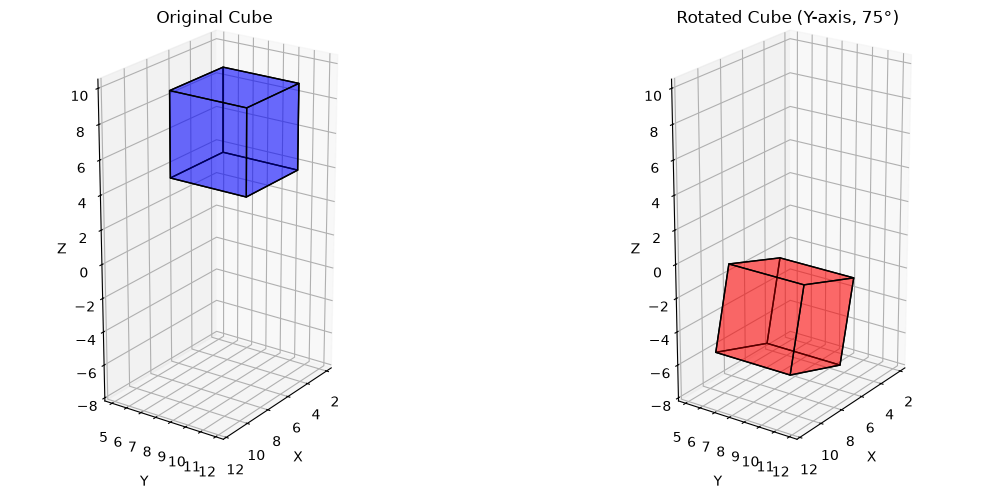

In [7]:
# Rotation about the Y-axis, theta = 75 degrees
theta_degrees = 75
rotation_angle = np.deg2rad(theta_degrees)
c = np.cos(rotation_angle)
s = np.sin(rotation_angle)

rotation_matrix = np.array([
    [c, 0, s],
    [0, 1, 0],
    [-s, 0, c],
])

rotation_matrix_h = np.array([
    [c, 0, s, 0],
    [0, 1, 0, 0],
    [-s, 0, c, 0],
    [0, 0, 0, 1],
])

print(f"theta = {theta_degrees} degrees = {rotation_angle:.6f} radians")
print("Rotation matrix about Y:")
print(rotation_matrix_h)

# Flatten is unnecessary here: 8 vertices, each a column
rotated_vertices = (rotation_matrix @ vertices.T).T
faces_rotated = cube_faces(rotated_vertices)

print("Original vertices:")
print(vertices)
print("Rotated vertices:")
print(rotated_vertices)

original_edge = np.linalg.norm(vertices[1] - vertices[0])
rotated_edge = np.linalg.norm(rotated_vertices[1] - rotated_vertices[0])
print(f"Edge before rotation: {original_edge:.4f}")
print(f"Edge after rotation:  {rotated_edge:.4f}")

combined = np.vstack([vertices, rotated_vertices])
pad = 1.5
mins = combined.min(axis=0) - pad
maxs = combined.max(axis=0) + pad
cube_limits = ((mins[0], maxs[0]), (mins[1], maxs[1]), (mins[2], maxs[2]))

fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(121, projection='3d')
ax1.add_collection3d(Poly3DCollection(
    faces, facecolors='blue', linewidths=1, edgecolors='black', alpha=0.35
))
style_axes(ax1, 'Original Cube', *cube_limits)

ax2 = fig.add_subplot(122, projection='3d')
ax2.add_collection3d(Poly3DCollection(
    faces_rotated, facecolors='red', linewidths=1, edgecolors='black', alpha=0.35
))
style_axes(ax2, 'Rotated Cube (Y-axis, 75°)', *cube_limits)

plt.tight_layout()
plt.show()